# Plotting data from CSV files

This notebook walks through some examples of reading in a CSV file from Google Sheets or another source, reading it into Python, and plotting the results.

In [2]:
# import relevant libraries

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

Use the link below to access a Google Sheet that has data from a pendulum experiment. The first column has the length of the pendulum, and the remaining columns show five independent measurements (i.e., five trials) of the period of the pendulum.

[test-pendulum-data (Google Sheets)](https://docs.google.com/spreadsheets/d/1WJNF3I4cV6c-0ZBeUK_RUgAE5y921WuzK_o0Cw3RanI/edit?usp=sharing)

Once you have opened the spreadsheet, follow thse steps:
1. Download the data as a CSV file by going to File > Download > Comma Separated Values (.csv) in Google Sheets.
2. Once you have downloaded the data to your computer, you can upload it to your Colab instance by using the folder icon (&#x1F4C1;) to open the Files menu and then click the upload button (&#x21E7;) to select and upload the file from your computer.

Then you can read the data file into Python using the method of your choosing. Two examples using Pandas and NumPy are given below.

## Importing the data using Pandas

Pandas (Python Data Analysis Library) is a data analysis library used for data science applications in Python. You can use it to read in a file as a "data frame", which is a handy way of storing tabular data. The cells below walk through the process of reading in our pendulum data with Pandas, viewing it, modifying it, and plotting it:

In [29]:
# read CSV file with pd.read_csv()

data_pd = pd.read_csv('test-pendulum-data.csv')

print(data_pd)


    length    t1    t2    t3    t4    t5
0     0.05  0.21  0.57  0.41  0.32  0.41
1     0.10  0.83  0.65  0.65  0.42  0.78
2     0.15  0.80  0.72  0.81  0.78  0.74
3     0.20  0.94  0.95  0.81  0.90  1.05
4     0.25  0.88  1.03  0.97  0.98  0.94
5     0.30  1.13  1.14  1.04  1.02  1.16
6     0.35  1.30  1.21  1.29  1.29  1.03
7     0.40  1.20  1.35  1.35  1.28  1.26
8     0.45  1.42  1.40  1.51  1.13  1.35
9     0.50  1.41  1.31  1.64  1.51  1.49
10    0.55  1.40  1.66  1.50  1.39  1.45
11    0.60  1.64  1.54  1.61  1.61  1.51
12    0.65  1.70  1.64  1.60  1.66  1.61
13    0.70  1.66  1.75  1.66  1.63  1.79
14    0.75  1.65  1.62  1.70  1.64  1.50
15    0.80  1.63  2.00  1.86  1.77  1.70
16    0.85  1.88  1.98  1.83  1.98  1.96
17    0.90  1.95  1.76  2.00  1.97  1.99


Notice that the data frame object shows the rows and columns of our data, and it automatically used the first row of our CSV file to define names for the different columns. This is handy, as it allows us to view individual columns or keep them together:

In [30]:
# define a list of all the column names
cols = data_pd.columns
print(cols)

Index(['length', 't1', 't2', 't3', 't4', 't5'], dtype='object')


In [31]:
# print just the length column
print(data_pd['length'])

0     0.05
1     0.10
2     0.15
3     0.20
4     0.25
5     0.30
6     0.35
7     0.40
8     0.45
9     0.50
10    0.55
11    0.60
12    0.65
13    0.70
14    0.75
15    0.80
16    0.85
17    0.90
Name: length, dtype: float64


In [32]:
# a different way to print just the length column
print(data_pd.length)

0     0.05
1     0.10
2     0.15
3     0.20
4     0.25
5     0.30
6     0.35
7     0.40
8     0.45
9     0.50
10    0.55
11    0.60
12    0.65
13    0.70
14    0.75
15    0.80
16    0.85
17    0.90
Name: length, dtype: float64


We can also easily create new columns, including columns calculated from existing columns. The cell below creates a new column that is the mean of all 5 trials for each length (i.e., the columns t1-t5). We also calculuate the standard deviation of each set of trials to define a column of uncertainties:

In [33]:
# create columns for mean and uncertainty

# take the mean of all the columns except the first
data_pd['t_mean'] = data_pd[cols[1:]].mean(axis=1)

# take the SD of all the columns except the first
data_pd['t_unc'] = data_pd[cols[1:]].std(axis=1)

# plot the updated DataFrame
print(data_pd)

    length    t1    t2    t3    t4    t5  t_mean     t_unc
0     0.05  0.21  0.57  0.41  0.32  0.41   0.384  0.132590
1     0.10  0.83  0.65  0.65  0.42  0.78   0.666  0.158840
2     0.15  0.80  0.72  0.81  0.78  0.74   0.770  0.038730
3     0.20  0.94  0.95  0.81  0.90  1.05   0.930  0.086891
4     0.25  0.88  1.03  0.97  0.98  0.94   0.960  0.055227
5     0.30  1.13  1.14  1.04  1.02  1.16   1.098  0.063403
6     0.35  1.30  1.21  1.29  1.29  1.03   1.224  0.114368
7     0.40  1.20  1.35  1.35  1.28  1.26   1.288  0.063797
8     0.45  1.42  1.40  1.51  1.13  1.35   1.362  0.142021
9     0.50  1.41  1.31  1.64  1.51  1.49   1.472  0.122556
10    0.55  1.40  1.66  1.50  1.39  1.45   1.480  0.109772
11    0.60  1.64  1.54  1.61  1.61  1.51   1.582  0.054498
12    0.65  1.70  1.64  1.60  1.66  1.61   1.642  0.040249
13    0.70  1.66  1.75  1.66  1.63  1.79   1.698  0.068337
14    0.75  1.65  1.62  1.70  1.64  1.50   1.622  0.074297
15    0.80  1.63  2.00  1.86  1.77  1.70   1.792  0.1441

Finally, we can make a plot with error bars using the new columns we have created along with the original length column:

Text(0, 0.5, 'Pendulum Period (s)')

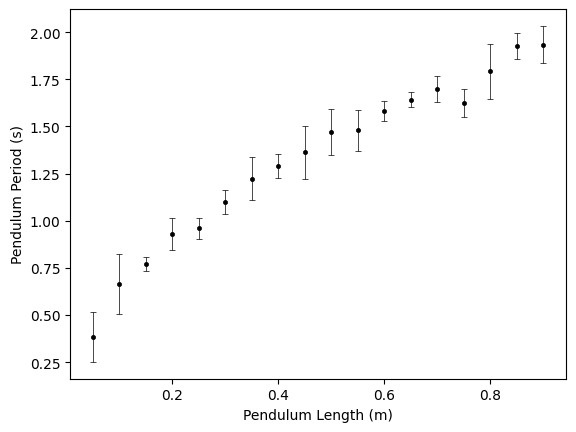

In [39]:
# create a plot using the columns of the pandas DataFrame

fig, ax = plt.subplots()
ax.errorbar(data_pd.length, data_pd.t_mean, data_pd.t_unc,fmt='k.',
            capsize=2,mew=0.5,elinewidth=0.5)
ax.set_xlabel('Pendulum Length (m)')
ax.set_ylabel('Pendulum Period (s)')

## Importing the data using NumPy

We can also just use the tools we've used previously to read in the data as a 2D NumPy array or a set of 1D NumPy arrays, for example using np.loadtxt():

In [12]:
# read CSV file with np.loadtxt()

# note skiprows=1 tells it to skip the row of column titles, and
# delimeter=',' tells Python that file uses commas to separate values
data_np = np.loadtxt('test-pendulum-data.csv',skiprows=1,delimiter=',')

print(data_np)

[[0.05 0.21 0.57 0.41 0.32 0.41]
 [0.1  0.83 0.65 0.65 0.42 0.78]
 [0.15 0.8  0.72 0.81 0.78 0.74]
 [0.2  0.94 0.95 0.81 0.9  1.05]
 [0.25 0.88 1.03 0.97 0.98 0.94]
 [0.3  1.13 1.14 1.04 1.02 1.16]
 [0.35 1.3  1.21 1.29 1.29 1.03]
 [0.4  1.2  1.35 1.35 1.28 1.26]
 [0.45 1.42 1.4  1.51 1.13 1.35]
 [0.5  1.41 1.31 1.64 1.51 1.49]
 [0.55 1.4  1.66 1.5  1.39 1.45]
 [0.6  1.64 1.54 1.61 1.61 1.51]
 [0.65 1.7  1.64 1.6  1.66 1.61]
 [0.7  1.66 1.75 1.66 1.63 1.79]
 [0.75 1.65 1.62 1.7  1.64 1.5 ]
 [0.8  1.63 2.   1.86 1.77 1.7 ]
 [0.85 1.88 1.98 1.83 1.98 1.96]
 [0.9  1.95 1.76 2.   1.97 1.99]]


NumPy does not have a way to designate column titles for a pure array object like this, but we can define individual 1D arrays from single columns or by applying mathematical functions to sets of columns as shown below:

In [14]:
# create separate arrays for the lengths, mean period, and uncertainty

L_array = data_np[:,0] # first column
T_array = np.mean(data_np[:,1:],axis=1) # mean of remaining columns
T_unc_array = np.std(data_np[:,1:],axis=1) # std. dev. of remaining columns

Now we can again plot the mean periods, uncertainties, and lengths of the pendula as we did before using the NumPy arrays we have created:

Text(0, 0.5, 'Pendulum Period (s)')

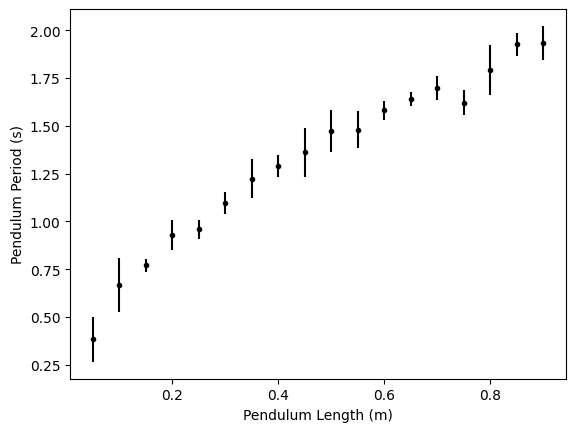

In [16]:
# create a plot using the arrays read in via np.loadtxt()

fig, ax = plt.subplots()
ax.errorbar(L_array, T_array, T_unc_array,fmt='k.',
            capsize=2,mew=0.5,elinewidth=0.5)
ax.set_xlabel('Pendulum Length (m)')
ax.set_ylabel('Pendulum Period (s)')

## Summary

As you can see, either of these methods can be used to read in the data and create the exact same plots---you may use the method that works best for you! The important thing is to format your data so that it is easy for Python to read into one of these file formats so that you can easily analyze and plot it.